In [59]:
import pandas as pd
import sys

sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [4]:
output_dir = '../3_outputs/sqY2H'

In [15]:
ppi_edges = pd.read_csv(f'{output_dir}/ppi_level_scores_minimal_update3.csv')
ppi_edges_mlh1 = ppi_edges[ppi_edges.symbol == 'MLH1']

# Remove duplicates by keeping the row with the highest db_mut_id for each variant-partner combination
ppi_edges_mlh1 = ppi_edges_mlh1.sort_values('db_mut_id', ascending=False).drop_duplicates(
    subset=['aa_change', 'ad_symbol'], 
    keep='first'
)

ppi_edges_mlh1

,symbol,aa_change,db_mut_id,ad_symbol,clinvar_clnsig_clean_pp_strict,consensus_score,wt_consensus_score,log2fc
779,MLH1,Lys751Arg,200902,ZNF212,Likely benign,477.837144,489.084918,-0.033497
1022,MLH1,Lys751Arg,200902,NME4,Likely benign,567.667308,344.050770,0.720776
1519,MLH1,Lys751Arg,200902,MAGEA8,Likely benign,414.170433,210.862777,0.970574
579,MLH1,Lys751Arg,200902,CCDC74B,Likely benign,236.029468,356.106650,-0.591289
1214,MLH1,Lys751Arg,200902,AES,Likely benign,641.384098,645.157347,-0.008449
...,...,...,...,...,...,...,...,...
656,MLH1,wt,0,SPERT,NaN,394.410917,394.410917,0.000000
1016,MLH1,wt,0,NME4,NaN,344.050770,344.050770,0.000000
1236,MLH1,wt,0,NFIX,NaN,139.524250,139.524250,0.000000
1509,MLH1,wt,0,MAGEA8,NaN,210.862777,210.862777,0.000000


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_56800/1660245.py:30: ClusterWarning: scipy.cluster: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage_matrix = linkage(variant_distances, method='average')


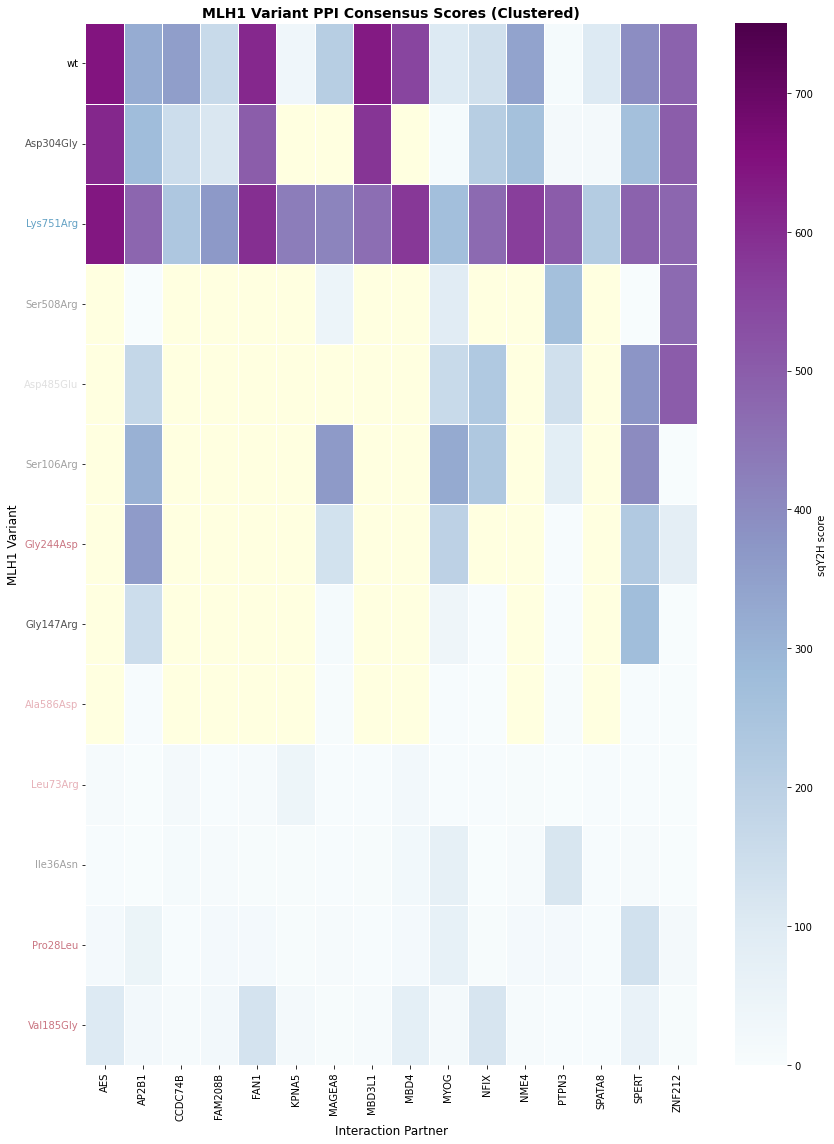

Total MLH1 variants: 13
Total interaction partners: 16
Matrix dimensions: (13, 16)

Missing data: 60 out of 208 total cells

ClinVar classification distribution:
clinvar_clnsig_clean_pp_strict
Pathogenic           3
VUS                  3
Conflicting          2
Likely pathogenic    2
Likely benign        1
Others               1
Name: count, dtype: int64


In [76]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import euclidean

# Pivot the data to create a matrix for the heatmap
# Rows: aa_change (variants), Columns: ad_symbol (partners)
heatmap_data = ppi_edges_mlh1.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')

# Compute pairwise Euclidean distances using only shared non-NaN values
n_variants = len(heatmap_data)
variant_distances = np.zeros((n_variants, n_variants))

for i in range(n_variants):
    for j in range(n_variants):
        row_i = heatmap_data.iloc[i]
        row_j = heatmap_data.iloc[j]
        
        # Find shared non-NaN indices
        shared_mask = ~(row_i.isna() | row_j.isna())
        
        if shared_mask.sum() >= 2:  # Need at least 2 shared points
            dist = euclidean(row_i[shared_mask], row_j[shared_mask])
            variant_distances[i, j] = dist
        else:
            variant_distances[i, j] = 0  # Set to 0 for linkage (will be treated as similar)

# Perform hierarchical clustering on the distance matrix
linkage_matrix = linkage(variant_distances, method='average')
dendro = dendrogram(linkage_matrix, no_plot=True)
clustered_order = dendro['leaves']

# Reorder the heatmap based on clustering
heatmap_data_sorted = heatmap_data.iloc[clustered_order]

heatmap_data_sorted = heatmap_data_sorted.iloc[::-1]

# Sort columns (partners) alphabetically
heatmap_data_sorted = heatmap_data_sorted[sorted(heatmap_data_sorted.columns)]

# Create variant to ClinVar classification mapping
variant_to_clnsig = ppi_edges_mlh1.drop_duplicates('aa_change').set_index('aa_change')['clinvar_clnsig_clean_pp_strict'].to_dict()


# Create the figure
fig, ax = plt.subplots(figsize=(12, 16))

# Create heatmap
sns.heatmap(heatmap_data_sorted, 
            cmap='BuPu',
            vmin=0, 
            vmax=750,
            cbar_kws={'label': 'sqY2H score'},
            linewidths=0.5,
            linecolor='white',
            square=False,
            ax=ax)

ax.set_facecolor('lightyellow')

# Customize labels
ax.set_xlabel('Interaction Partner', fontsize=12)
ax.set_ylabel('MLH1 Variant', fontsize=12)
ax.set_title('MLH1 Variant PPI Consensus Scores (Clustered)', fontsize=14, fontweight='bold')

# Rotate x-axis labels for better readability
plt.xticks(rotation=90, ha='center')
plt.yticks(rotation=0)

# Color-code y-axis labels by ClinVar classification
for tick_label in ax.get_yticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')  # Default to black if not found
    tick_label.set_color(color)

plt.tight_layout()
plt.savefig(f'{output_dir}/MLH1_PPI_heatmap_clustered.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"Total MLH1 variants: {len(heatmap_data_sorted)}")
print(f"Total interaction partners: {len(heatmap_data_sorted.columns)}")
print(f"Matrix dimensions: {heatmap_data_sorted.shape}")
print(f"\nMissing data: {heatmap_data.isna().sum().sum()} out of {heatmap_data.size} total cells")

# Print ClinVar distribution
print("\nClinVar classification distribution:")
print(ppi_edges_mlh1.drop_duplicates('aa_change')['clinvar_clnsig_clean_pp_strict'].value_counts())

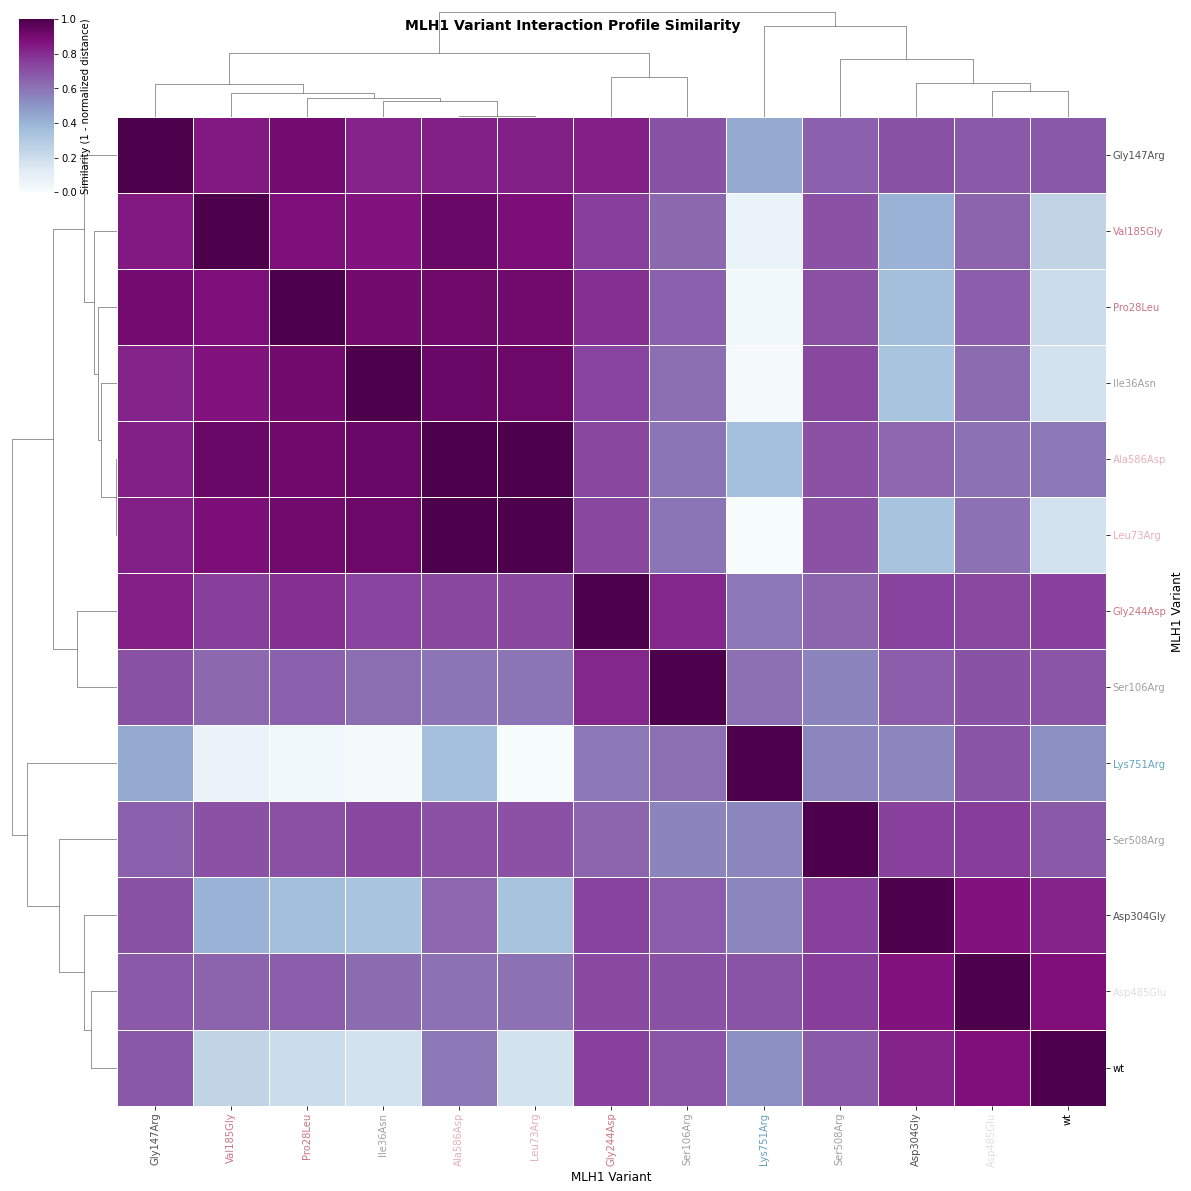

Total MLH1 variants: 13
Matrix dimensions: (13, 13)

Similarity range: 0.000 to 1.000


In [77]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.spatial.distance import euclidean, squareform
from scipy.cluster.hierarchy import linkage

# Pivot the data to create a matrix for the heatmap
heatmap_data = ppi_edges_mlh1.pivot(index='aa_change', columns='ad_symbol', values='consensus_score')

# Compute pairwise Euclidean distances using only shared non-NaN values
n_variants = len(heatmap_data)
variant_distances = np.zeros((n_variants, n_variants))

for i in range(n_variants):
    for j in range(n_variants):
        row_i = heatmap_data.iloc[i]
        row_j = heatmap_data.iloc[j]
        
        # Find shared non-NaN indices
        shared_mask = ~(row_i.isna() | row_j.isna())
        
        if shared_mask.sum() >= 2:  # Need at least 2 shared points
            dist = euclidean(row_i[shared_mask], row_j[shared_mask])
            variant_distances[i, j] = dist
        else:
            variant_distances[i, j] = 0  # No shared data points

# Convert distance matrix to condensed form for linkage
condensed_distances = squareform(variant_distances)

# Perform hierarchical clustering on the distance matrix directly
linkage_matrix = linkage(condensed_distances, method='average')

# Convert distances to similarity for visualization
max_dist = np.max(variant_distances)
variant_similarity = 1 - (variant_distances / max_dist)

# Convert to DataFrame
variant_similarity_df = pd.DataFrame(
    variant_similarity,
    index=heatmap_data.index,
    columns=heatmap_data.index
)

# Create clustered heatmap using pre-computed linkage
g = sns.clustermap(
    variant_similarity_df,
    cmap='BuPu',
    vmin=0,
    vmax=1,
    figsize=(16, 16),
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Similarity (1 - normalized distance)', 'shrink': 0.5},
    dendrogram_ratio=0.1,
    cbar_pos=(0.02, 0.83, 0.03, 0.15),
    row_linkage=linkage_matrix,  # Use pre-computed linkage
    col_linkage=linkage_matrix,  # Same for columns
    row_cluster=True,
    col_cluster=True
)

# Customize axis labels
g.ax_heatmap.set_xlabel('MLH1 Variant', fontsize=12)
g.ax_heatmap.set_ylabel('MLH1 Variant', fontsize=12)

# Rotate labels
plt.setp(g.ax_heatmap.xaxis.get_majorticklabels(), rotation=90, ha='center')
plt.setp(g.ax_heatmap.yaxis.get_majorticklabels(), rotation=0)

# Color-code y-axis labels by ClinVar classification
for tick_label in g.ax_heatmap.get_yticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')
    tick_label.set_color(color)

# Color-code x-axis labels by ClinVar classification
for tick_label in g.ax_heatmap.get_xticklabels():
    variant = tick_label.get_text()
    clnsig = variant_to_clnsig.get(variant, None)
    color = palette_dict['clinvar_clnsig_clean_pp_strict'].get(clnsig, 'black')
    tick_label.set_color(color)


# Add title
g.fig.suptitle('MLH1 Variant Interaction Profile Similarity', 
               fontsize=14, fontweight='bold', y=0.98)

plt.savefig(f'{output_dir}/MLH1_variant_similarity_clustered.pdf', 
            format='pdf', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"Total MLH1 variants: {len(variant_similarity_df)}")
print(f"Matrix dimensions: {variant_similarity_df.shape}")
print(f"\nSimilarity range: {variant_similarity.min():.3f} to {variant_similarity.max():.3f}")